# NP3-233-CD — Outage Forecast Drift During Winter Storm Uri

The outage capacity report (NP3-233-CD) is a **rolling forecast**, not historical actuals.
Each hourly posting revises the 168-hour forward window. Once an hour passes, its row
disappears from all future docs — there is no "realized" snapshot.

**Question:** During Winter Storm Uri (Feb 13–17, 2021), how much did the outage forecast
drift between postings? If the D−1 hour-23 forecast is close to the last-available forecast
for each hour, we can use the simpler one-doc-per-day extraction. If it diverges badly
during the crisis, we need the more expensive all-docs approach.

**Method:** For each day of Uri, compare the TotalResourceMW values from:
- The D−1 hour-23 doc (~13–24h ahead forecast)
- The earliest doc on day D (hour-0/1, ~1–24h ahead)
- The last doc before each hour (closest-to-real-time forecast)

Depends on: `05_np3_233_cd_outage_cap_endpoint_check.ipynb` (endpoint verified).

In [1]:
import os, time, io, zipfile
import requests
import pandas as pd
import numpy as np
from datetime import date, timedelta
from dotenv import load_dotenv

load_dotenv()

_TOKEN_URL = (
    'https://ercotb2c.b2clogin.com'
    '/ercotb2c.onmicrosoft.com'
    '/B2C_1_PUBAPI-ROPC-FLOW'
    '/oauth2/v2.0/token'
)
CLIENT_ID = 'fec253ea-0d06-4272-a5e6-b478baeecd70'

_token_cache = {'token': None, 'expires_at': 0.0}

def _get_token() -> str:
    if _token_cache['token'] and time.time() < _token_cache['expires_at']:
        return _token_cache['token']
    resp = requests.post(_TOKEN_URL, data={
        'username'     : os.environ['ERCOT_USERNAME'],
        'password'     : os.environ['ERCOT_PASSWORD'],
        'grant_type'   : 'password',
        'client_id'    : CLIENT_ID,
        'scope'        : f'openid {CLIENT_ID} offline_access',
        'response_type': 'id_token',
    }, timeout=(10, 60))
    resp.raise_for_status()
    body = resp.json()
    _token_cache['token']      = body['id_token']
    _token_cache['expires_at'] = time.time() + int(body.get('expires_in', 3600)) - 60
    return _token_cache['token']

def _hdrs() -> dict:
    return {
        'Authorization'            : f'Bearer {_get_token()}',
        'Ocp-Apim-Subscription-Key': os.environ['ERCOT_SUBSCRIPTION_KEY'],
    }

ARCHIVE_URL = 'https://api.ercot.com/api/public-reports/archive/np3-233-cd'

def _retry_request(fn, max_retries=3, base_wait=30):
    """Retry a request function on 429 rate-limit errors."""
    for attempt in range(max_retries + 1):
        try:
            return fn()
        except requests.HTTPError as e:
            if e.response.status_code == 429 and attempt < max_retries:
                wait = base_wait * (2 ** attempt)
                print(f'  Rate limited, waiting {wait}s (attempt {attempt+1}/{max_retries})...')
                time.sleep(wait)
            else:
                raise

def _download_archive_csv(doc_id):
    """Download a single archive doc and return its CSV as a DataFrame."""
    def _do():
        dl = requests.post(f'{ARCHIVE_URL}/download', headers=_hdrs(),
                           json={'docIds': [doc_id]}, timeout=(10, 120))
        dl.raise_for_status()
        return dl
    dl = _retry_request(_do)
    with zipfile.ZipFile(io.BytesIO(dl.content)) as outer_zf:
        inner_zips = [n for n in outer_zf.namelist() if n.endswith('.zip')]
        csv_files  = [n for n in outer_zf.namelist() if n.endswith('.csv')]
        if csv_files:
            return pd.read_csv(outer_zf.open(csv_files[0]))
        inner_buf = io.BytesIO(outer_zf.read(inner_zips[0]))
        with zipfile.ZipFile(inner_buf) as inner_zf:
            csv_name = [n for n in inner_zf.namelist() if n.endswith('.csv')][0]
            return pd.read_csv(inner_zf.open(csv_name))

def _list_docs(post_from, post_to, page=1, size=100):
    """List archive docs in a posting-time window."""
    def _do():
        resp = requests.get(ARCHIVE_URL, headers=_hdrs(), params={
            'postDatetimeFrom': post_from, 'postDatetimeTo': post_to,
            'page': page, 'size': size,
        }, timeout=30)
        resp.raise_for_status()
        return resp.json()
    return _retry_request(_do)

print('Auth OK —', _get_token()[:20], '...')

Auth OK — eyJhbGciOiJSUzI1NiIs ...


---
## 1 — Collect all Uri-period archive docs

Download every posting from Feb 12 (D−1 for Feb 13) through Feb 17, 2021.
Extract rows for the Uri core dates (Feb 13–17) from each doc.

In [2]:
URI_START = '2021-02-13'
URI_END   = '2021-02-17'
# Fetch docs from D-1 of URI_START through end of URI_END
FETCH_FROM = '2021-02-12T00:00'
FETCH_TO   = '2021-02-17T23:59'

URI_DATES_STR = set()  # MM/DD/YYYY format used in archive CSV
d = date(2021, 2, 13)
while d <= date(2021, 2, 17):
    URI_DATES_STR.add(d.strftime('%m/%d/%Y'))
    d += timedelta(days=1)

# List all docs in the window
all_doc_ids = []
page = 1
while True:
    body = _list_docs(FETCH_FROM, FETCH_TO, page=page, size=100)
    archives = body.get('archives', [])
    all_doc_ids.extend(archives)
    total = body['_meta']['totalRecords']
    if page * 100 >= total:
        break
    page += 1
    time.sleep(0.3)

print(f'Total docs Feb 12–17: {len(all_doc_ids)}')
print(f'First: {all_doc_ids[-1]["postDatetime"]}')  # oldest last (desc order)
print(f'Last:  {all_doc_ids[0]["postDatetime"]}')

Total docs Feb 12–17: 144
First: 2021-02-12T00:01:12.962
Last:  2021-02-17T23:01:10.446


In [3]:
# Download each doc and extract Uri-date rows
# ~140 docs × ~2s each ≈ 5 min
rows = []
errors = []
for i, doc in enumerate(all_doc_ids):
    doc_id = doc['docId']
    posted = doc['postDatetime']
    try:
        df = _download_archive_csv(doc_id)
        uri_rows = df[df['Date'].isin(URI_DATES_STR)].copy()
        if not uri_rows.empty:
            uri_rows['postDatetime'] = posted
            rows.append(uri_rows)
    except Exception as e:
        errors.append((doc_id, posted, str(e)))
    if (i + 1) % 20 == 0:
        print(f'  {i+1}/{len(all_doc_ids)} docs processed...')
    time.sleep(1.5)

df_uri = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
print(f'\nTotal Uri-date rows collected: {len(df_uri):,}')
print(f'Errors: {len(errors)}')
if errors:
    for doc_id, posted, err in errors[:5]:
        print(f'  {posted}: {err}')

  20/144 docs processed...


  Rate limited, waiting 30s (attempt 1/3)...


  40/144 docs processed...


  Rate limited, waiting 30s (attempt 1/3)...


  60/144 docs processed...


...

  100/144 docs processed...


  Rate limited, waiting 30s (attempt 1/3)...


  120/144 docs processed...


  140/144 docs processed...



Total Uri-date rows collected: 10,140
Errors: 0


In [4]:
# Parse timestamps for analysis
df_uri['posted_dt'] = pd.to_datetime(df_uri['postDatetime'])
df_uri['target_date'] = pd.to_datetime(df_uri['Date'], format='%m/%d/%Y')
df_uri['posted_date'] = df_uri['posted_dt'].dt.date
df_uri['posted_hour'] = df_uri['posted_dt'].dt.hour

# Lead time: hours between posting and the target hour
df_uri['target_dt'] = df_uri['target_date'] + pd.to_timedelta(df_uri['HourEnding'], unit='h')
df_uri['lead_hours'] = (df_uri['target_dt'] - df_uri['posted_dt']).dt.total_seconds() / 3600

print(f'Date range: {df_uri["Date"].unique()}')
print(f'Posting range: {df_uri["posted_dt"].min()} → {df_uri["posted_dt"].max()}')
print(f'Lead time range: {df_uri["lead_hours"].min():.1f}h → {df_uri["lead_hours"].max():.1f}h')
print(f'\nRows per target date:')
print(df_uri.groupby('Date').size().to_string())

Date range: <ArrowStringArray>
['02/17/2021', '02/16/2021', '02/15/2021', '02/14/2021', '02/13/2021']
Length: 5, dtype: str
Posting range: 2021-02-12 00:01:12.962000 → 2021-02-17 23:01:10.446000
Lead time range: 1.0h → 144.0h

Rows per target date:
Date
02/13/2021     876
02/14/2021    1452
02/15/2021    2028
02/16/2021    2604
02/17/2021    3180


---
## 2 — Forecast drift: D−1 hour-23 vs last-available

For each (target_date, HourEnding), compare:
- **D−1 h23:** the value from the hour-23 doc posted the day before (~13–24h lead)
- **Last available:** the value from the last posting before that hour (~1h lead)
- **Drift:** absolute difference in MW

In [5]:
drift_rows = []

for (tgt_date_str, he), grp in df_uri.groupby(['Date', 'HourEnding']):
    grp_sorted = grp.sort_values('posted_dt')
    tgt_date = grp_sorted['target_date'].iloc[0].date()
    d_minus_1 = tgt_date - timedelta(days=1)

    # D-1 hour-23: posting from previous day, hour 22:30–23:59
    d1_mask = ((grp_sorted['posted_date'] == d_minus_1) &
               (grp_sorted['posted_hour'] == 23))
    d1_rows = grp_sorted[d1_mask]

    # Last available: posting with smallest positive lead time
    future = grp_sorted[grp_sorted['lead_hours'] > 0]
    last_avail = future.iloc[-1] if not future.empty else None  # largest posted_dt with lead>0
    # Actually we want the one closest to the hour — smallest positive lead
    last_avail = future.sort_values('lead_hours').iloc[0] if not future.empty else None

    if d1_rows.empty or last_avail is None:
        continue

    mw_d1   = d1_rows.iloc[0]['TotalResourceMW']
    mw_last = last_avail['TotalResourceMW']
    lead_d1   = d1_rows.iloc[0]['lead_hours']
    lead_last = last_avail['lead_hours']

    drift_rows.append({
        'target_date': tgt_date_str,
        'HourEnding': he,
        'mw_d1_h23': mw_d1,
        'lead_d1_h23': lead_d1,
        'mw_last_avail': mw_last,
        'lead_last_avail': lead_last,
        'drift_mw': mw_last - mw_d1,
        'drift_abs_mw': abs(mw_last - mw_d1),
        'drift_pct': abs(mw_last - mw_d1) / mw_d1 * 100 if mw_d1 > 0 else np.nan,
    })

df_drift = pd.DataFrame(drift_rows)
print(f'Drift comparisons: {len(df_drift)} (target_date × HourEnding pairs)')
print(f'\nDrift summary (absolute MW):')
print(df_drift['drift_abs_mw'].describe().to_string())
print(f'\nDrift summary (% of D-1 value):')
print(df_drift['drift_pct'].describe().to_string())

Drift comparisons: 120 (target_date × HourEnding pairs)

Drift summary (absolute MW):
count      120.000000
mean      5445.600000
std       5698.353448
min         59.000000
25%        561.500000
50%       4100.000000
75%       7725.750000
max      19251.000000

Drift summary (% of D-1 value):
count    120.000000
mean      35.083441
std       46.080744
min        0.421278
25%        4.322881
50%       16.739214
75%       35.531905
max      158.382083


In [6]:
# Drift breakdown by Uri day
print('=== Forecast drift by Uri day ===')
print('(D-1 hour-23 forecast vs closest-to-real-time forecast)\n')

for tgt_date, day_grp in df_drift.groupby('target_date'):
    print(f'{tgt_date}:')
    print(f'  D-1 h23 MW range:     {day_grp["mw_d1_h23"].min():,.0f} – {day_grp["mw_d1_h23"].max():,.0f}')
    print(f'  Last-avail MW range:  {day_grp["mw_last_avail"].min():,.0f} – {day_grp["mw_last_avail"].max():,.0f}')
    print(f'  Abs drift:  mean={day_grp["drift_abs_mw"].mean():,.0f} MW, '
          f'max={day_grp["drift_abs_mw"].max():,.0f} MW')
    print(f'  % drift:    mean={day_grp["drift_pct"].mean():.1f}%, '
          f'max={day_grp["drift_pct"].max():.1f}%')
    print()

=== Forecast drift by Uri day ===
(D-1 hour-23 forecast vs closest-to-real-time forecast)

02/13/2021:
  D-1 h23 MW range:     13,284 – 14,005
  Last-avail MW range:  12,544 – 14,379
  Abs drift:  mean=347 MW, max=862 MW
  % drift:    mean=2.6%, max=6.4%

02/14/2021:
  D-1 h23 MW range:     11,334 – 13,564
  Last-avail MW range:  12,743 – 14,587
  Abs drift:  mean=820 MW, max=1,759 MW
  % drift:    mean=6.4%, max=13.7%

02/15/2021:
  D-1 h23 MW range:     11,700 – 12,670
  Last-avail MW range:  13,983 – 31,777
  Abs drift:  mean=13,815 MW, max=19,251 MW
  % drift:    mean=112.4%, max=158.4%

02/16/2021:
  D-1 h23 MW range:     15,044 – 26,473
  Last-avail MW range:  26,747 – 32,379
  Abs drift:  mean=7,347 MW, max=12,216 MW
  % drift:    mean=33.2%, max=81.2%

02/17/2021:
  D-1 h23 MW range:     16,361 – 27,293
  Last-avail MW range:  21,825 – 31,703
  Abs drift:  mean=4,898 MW, max=7,245 MW
  % drift:    mean=20.9%, max=33.4%



---
## 3 — Outage trajectory during Uri

Plot how TotalResourceMW evolved hour-by-hour across the storm,
comparing the D−1 forecast to the last-available forecast.

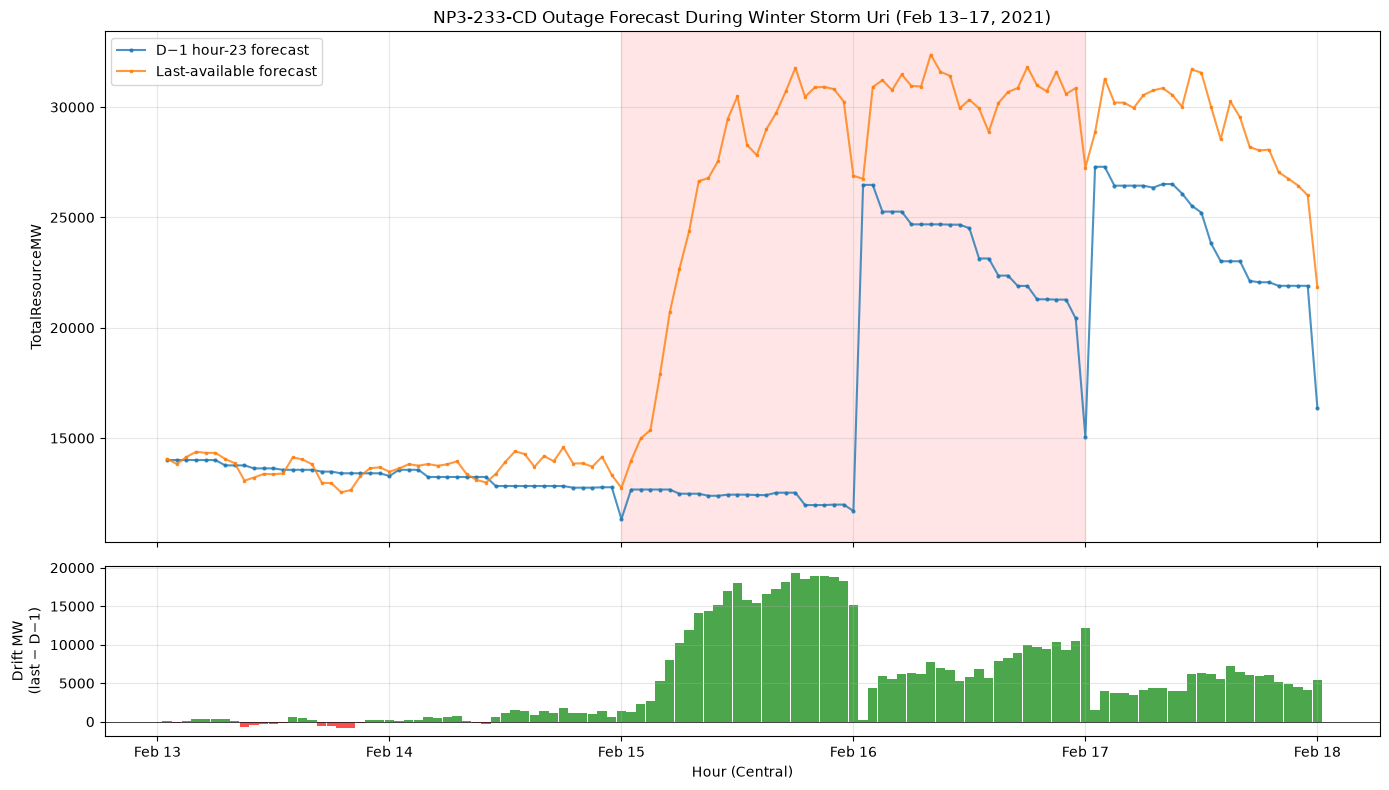

Saved to 01_data/3_analysis/np3_233_cd_uri_forecast_drift.png


In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_drift['target_dt'] = pd.to_datetime(df_drift['target_date'], format='%m/%d/%Y') + \
                         pd.to_timedelta(df_drift['HourEnding'], unit='h')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1]})

# Top: MW trajectories
ax = axes[0]
ax.plot(df_drift['target_dt'], df_drift['mw_d1_h23'], 'o-',
        label='D−1 hour-23 forecast', markersize=2, alpha=0.8)
ax.plot(df_drift['target_dt'], df_drift['mw_last_avail'], 's-',
        label='Last-available forecast', markersize=2, alpha=0.8)
ax.set_ylabel('TotalResourceMW')
ax.set_title('NP3-233-CD Outage Forecast During Winter Storm Uri (Feb 13–17, 2021)')
ax.legend()
ax.grid(True, alpha=0.3)

# Shade the peak Uri period (Feb 15–16)
ax.axvspan(pd.Timestamp('2021-02-15'), pd.Timestamp('2021-02-17'),
           alpha=0.1, color='red', label='Peak Uri')

# Bottom: drift
ax2 = axes[1]
colors = ['green' if d >= 0 else 'red' for d in df_drift['drift_mw']]
ax2.bar(df_drift['target_dt'], df_drift['drift_mw'], width=0.04, color=colors, alpha=0.7)
ax2.axhline(0, color='black', linewidth=0.5)
ax2.set_ylabel('Drift MW\n(last − D−1)')
ax2.set_xlabel('Hour (Central)')
ax2.grid(True, alpha=0.3)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

plt.tight_layout()
from pathlib import Path
out_path = Path('../../01_data/3_analysis')
out_path.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path / 'np3_233_cd_uri_forecast_drift.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to 01_data/3_analysis/np3_233_cd_uri_forecast_drift.png')

---
## 4 — Drift during a normal week (baseline comparison)

Compare the same drift metric for a quiet week to establish the baseline.

In [8]:
# Pick a normal winter week: Jan 11–15, 2021 (no extreme weather)
BASELINE_FROM = '2021-01-10T00:00'  # D-1 for Jan 11
BASELINE_TO   = '2021-01-15T23:59'
BASELINE_DATES = set()
d = date(2021, 1, 11)
while d <= date(2021, 1, 15):
    BASELINE_DATES.add(d.strftime('%m/%d/%Y'))
    d += timedelta(days=1)

# List + download baseline docs
bl_doc_ids = []
page = 1
while True:
    body = _list_docs(BASELINE_FROM, BASELINE_TO, page=page, size=100)
    bl_doc_ids.extend(body.get('archives', []))
    if page * 100 >= body['_meta']['totalRecords']:
        break
    page += 1
    time.sleep(1.0)

print(f'Baseline docs (Jan 10–15): {len(bl_doc_ids)}')

bl_rows = []
for i, doc in enumerate(bl_doc_ids):
    try:
        df = _download_archive_csv(doc['docId'])
        bl = df[df['Date'].isin(BASELINE_DATES)].copy()
        if not bl.empty:
            bl['postDatetime'] = doc['postDatetime']
            bl_rows.append(bl)
    except Exception:
        pass
    if (i + 1) % 20 == 0:
        print(f'  {i+1}/{len(bl_doc_ids)} docs...')
    time.sleep(1.5)

df_bl = pd.concat(bl_rows, ignore_index=True) if bl_rows else pd.DataFrame()
df_bl['posted_dt'] = pd.to_datetime(df_bl['postDatetime'])
df_bl['target_date'] = pd.to_datetime(df_bl['Date'], format='%m/%d/%Y')
df_bl['posted_date'] = df_bl['posted_dt'].dt.date
df_bl['posted_hour'] = df_bl['posted_dt'].dt.hour
df_bl['target_dt'] = df_bl['target_date'] + pd.to_timedelta(df_bl['HourEnding'], unit='h')
df_bl['lead_hours'] = (df_bl['target_dt'] - df_bl['posted_dt']).dt.total_seconds() / 3600

print(f'Baseline rows collected: {len(df_bl):,}')

Baseline docs (Jan 10–15): 144


  Rate limited, waiting 30s (attempt 1/3)...


  20/144 docs...


  Rate limited, waiting 30s (attempt 1/3)...


  40/144 docs...


...

  100/144 docs...


  120/144 docs...


  Rate limited, waiting 30s (attempt 1/3)...


  140/144 docs...


Baseline rows collected: 10,140


In [9]:
# Compute baseline drift the same way
bl_drift_rows = []
for (tgt_date_str, he), grp in df_bl.groupby(['Date', 'HourEnding']):
    grp_sorted = grp.sort_values('posted_dt')
    tgt_date = grp_sorted['target_date'].iloc[0].date()
    d_minus_1 = tgt_date - timedelta(days=1)

    d1_mask = ((grp_sorted['posted_date'] == d_minus_1) &
               (grp_sorted['posted_hour'] == 23))
    d1_rows = grp_sorted[d1_mask]

    future = grp_sorted[grp_sorted['lead_hours'] > 0]
    last_avail = future.sort_values('lead_hours').iloc[0] if not future.empty else None

    if d1_rows.empty or last_avail is None:
        continue

    mw_d1   = d1_rows.iloc[0]['TotalResourceMW']
    mw_last = last_avail['TotalResourceMW']

    bl_drift_rows.append({
        'target_date': tgt_date_str,
        'HourEnding': he,
        'drift_abs_mw': abs(mw_last - mw_d1),
        'drift_pct': abs(mw_last - mw_d1) / mw_d1 * 100 if mw_d1 > 0 else np.nan,
    })

df_bl_drift = pd.DataFrame(bl_drift_rows)

print('=== Drift comparison: Uri vs Normal week ===')
print(f'\nUri (Feb 13–17, 2021):   n={len(df_drift)}')
print(f'  Abs drift:  mean={df_drift["drift_abs_mw"].mean():,.0f} MW, '
      f'median={df_drift["drift_abs_mw"].median():,.0f} MW, '
      f'max={df_drift["drift_abs_mw"].max():,.0f} MW')
print(f'  % drift:    mean={df_drift["drift_pct"].mean():.1f}%, '
      f'median={df_drift["drift_pct"].median():.1f}%, '
      f'max={df_drift["drift_pct"].max():.1f}%')

print(f'\nBaseline (Jan 11–15, 2021):   n={len(df_bl_drift)}')
print(f'  Abs drift:  mean={df_bl_drift["drift_abs_mw"].mean():,.0f} MW, '
      f'median={df_bl_drift["drift_abs_mw"].median():,.0f} MW, '
      f'max={df_bl_drift["drift_abs_mw"].max():,.0f} MW')
print(f'  % drift:    mean={df_bl_drift["drift_pct"].mean():.1f}%, '
      f'median={df_bl_drift["drift_pct"].median():.1f}%, '
      f'max={df_bl_drift["drift_pct"].max():.1f}%')

=== Drift comparison: Uri vs Normal week ===

Uri (Feb 13–17, 2021):   n=120
  Abs drift:  mean=5,446 MW, median=4,100 MW, max=19,251 MW
  % drift:    mean=35.1%, median=16.7%, max=158.4%

Baseline (Jan 11–15, 2021):   n=120
  Abs drift:  mean=418 MW, median=307 MW, max=1,746 MW
  % drift:    mean=4.2%, median=3.2%, max=22.3%


---
## 5 — Conclusion

**Interpret the drift results above to decide the extraction strategy:**
- If drift is small (< ~5%) even during Uri → D−1 hour-23 is sufficient
- If drift is large during Uri but small otherwise → document the caveat
- If drift is large everywhere → need all-docs extraction

In [10]:
uri_mean_pct = df_drift['drift_pct'].mean()
uri_max_pct  = df_drift['drift_pct'].max()
bl_mean_pct  = df_bl_drift['drift_pct'].mean()
bl_max_pct   = df_bl_drift['drift_pct'].max()

print('=== EXTRACTION STRATEGY RECOMMENDATION ===')
print(f'\nUri mean drift:      {uri_mean_pct:.1f}%')
print(f'Uri max drift:       {uri_max_pct:.1f}%')
print(f'Baseline mean drift: {bl_mean_pct:.1f}%')
print(f'Baseline max drift:  {bl_max_pct:.1f}%')

if uri_max_pct < 10:
    print('\n→ Drift is small even during Uri. D−1 hour-23 extraction is acceptable.')
elif bl_max_pct < 10 and uri_max_pct >= 10:
    print(f'\n→ Drift is small normally ({bl_max_pct:.0f}%) but elevated during Uri '
          f'({uri_max_pct:.0f}%). Document the caveat; D−1 h23 may still be acceptable '
          'given that Uri outages are massive regardless of forecast timing.')
else:
    print('\n→ Drift is large in both periods. Consider all-docs extraction '
          'or accept the approximation with documented caveats.')

=== EXTRACTION STRATEGY RECOMMENDATION ===

Uri mean drift:      35.1%
Uri max drift:       158.4%
Baseline mean drift: 4.2%
Baseline max drift:  22.3%

→ Drift is large in both periods. Consider all-docs extraction or accept the approximation with documented caveats.
